# Лабораторная работа №3
## Классификация: логистическая регрессия

**Датасет:** Bank Marketing (`bank-full.csv`), 45 211 наблюдений, 16 признаков и бинарная целевая переменная `y`.

**Цель:** Научиться строить модели логистической регрессии для решения задач
бинарной классификации.

## Подготовка библиотек и загрузка данных

In [1]:
import warnings, os
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay, classification_report
)
from sklearn.utils import resample
from sklearn.base import clone

RANDOM_STATE = 42
df = pd.read_csv('../data/bank-full.csv', sep=";")
df["y"] = df["y"].map({"no": 0, "yes": 1})

print("Размерность:", df.shape)
display(df.head())
print("\nТипы данных:")
display(df.dtypes.to_frame("dtype"))

Размерность: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,0



Типы данных:


,dtype
age,int64
job,str
marital,str
education,str
default,str
balance,int64
housing,str
loan,str
contact,str
day,int64


## Задание 1.1. Предметная область, единица наблюдения, целевая переменная и цена ошибок

In [2]:
print("Предметная область: банковский телефонный маркетинг.")
print("Единица наблюдения: один клиент/контакт в рамках маркетинговой кампании.")
print("Целевая переменная y: 1 - клиент оформил срочный депозит; 0 — не оформил.")
print("Ошибка I рода (FP): модель обещает отклик, но клиент не оформляет депозит.")
print("Практическая цена FP: лишние затраты на контакт/ресурсы кампании.")
print("Ошибка II рода (FN): модель прогнозирует отказ, но клиент мог бы оформить депозит.")
print("Практическая цена FN: упущенный потенциальный клиент и доход.")

Предметная область: банковский телефонный маркетинг.
Единица наблюдения: один клиент/контакт в рамках маркетинговой кампании.
Целевая переменная y: 1 - клиент оформил срочный депозит; 0 — не оформил.
Ошибка I рода (FP): модель обещает отклик, но клиент не оформляет депозит.
Практическая цена FP: лишние затраты на контакт/ресурсы кампании.
Ошибка II рода (FN): модель прогнозирует отказ, но клиент мог бы оформить депозит.
Практическая цена FN: упущенный потенциальный клиент и доход.


## Задание 1.2. Положительный класс

In [3]:
positive_class = 1
print("Положительный класс: y=1 (yes), поскольку это интересующий бизнес-результат - оформление депозита.")
print("Отрицательный класс: y=0 (no).")

Положительный класс: y=1 (yes), поскольку это интересующий бизнес-результат - оформление депозита.
Отрицательный класс: y=0 (no).


## Задание 1.3. Распределения числовых признаков по классам

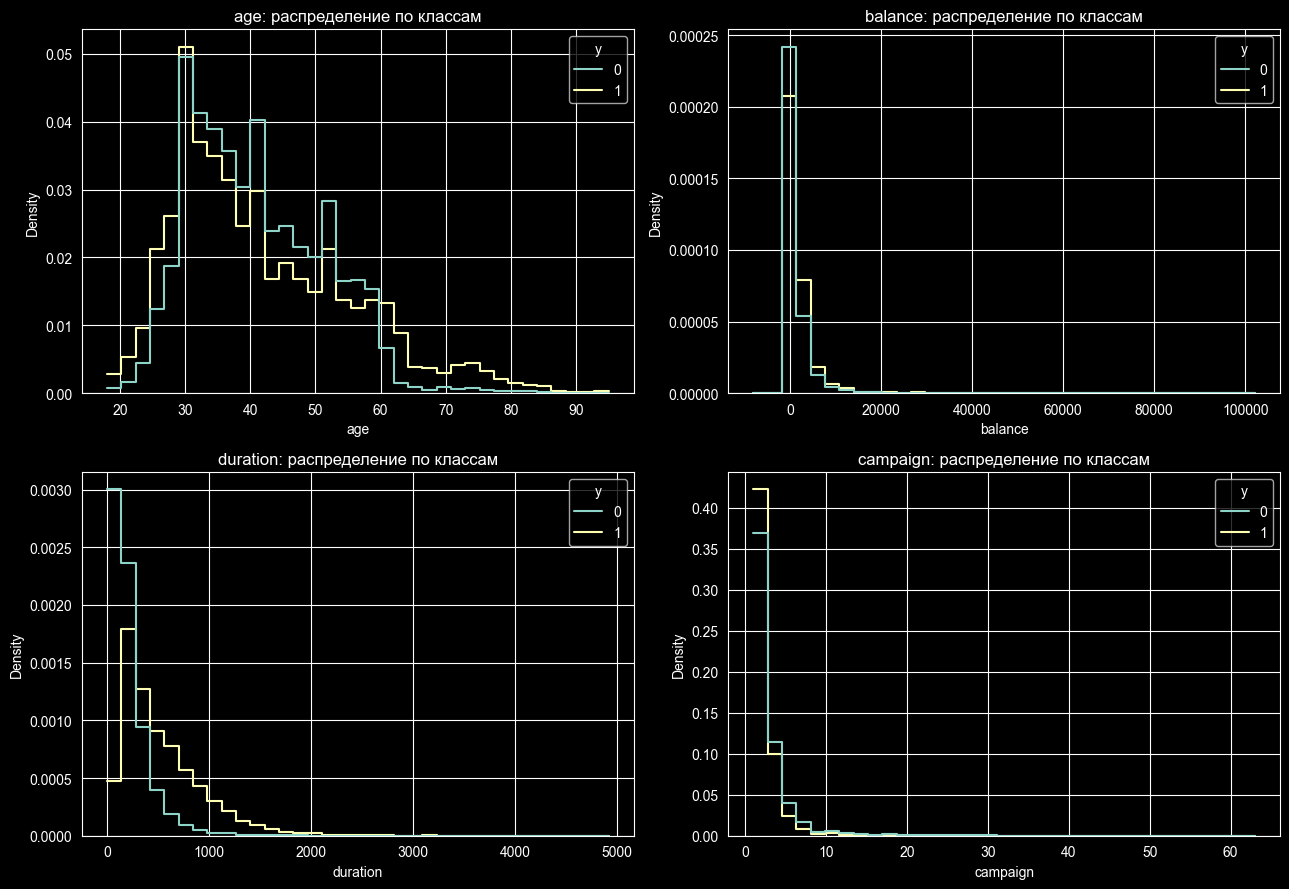

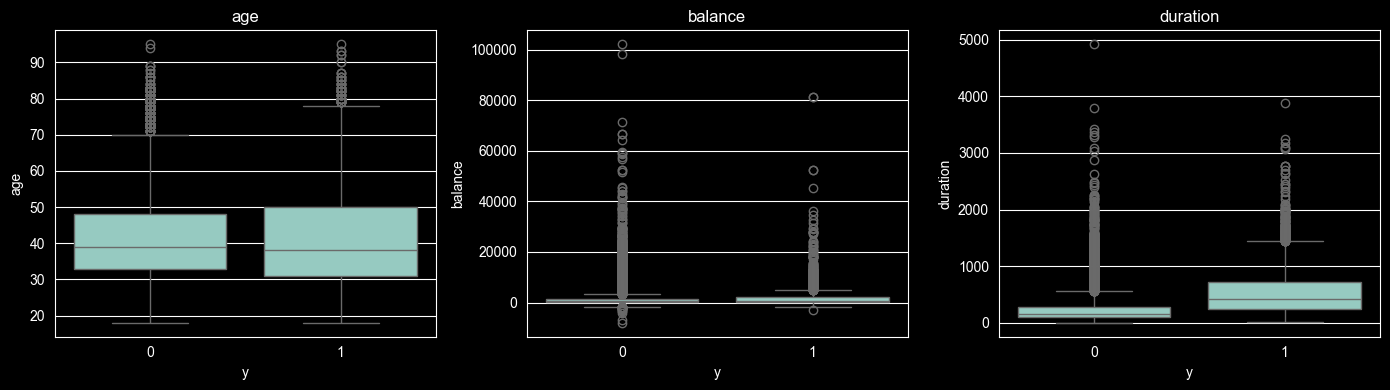

In [4]:
numeric_cols_all = df.select_dtypes(include=np.number).columns.drop("y").tolist()
plot_cols = ["age", "balance", "duration", "campaign"]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for col, ax in zip(plot_cols, axes.ravel()):
    sns.histplot(data=df, x=col, hue="y", stat="density", common_norm=False,
                 bins=35, element="step", fill=False, ax=ax)
    ax.set_title(f"{col}: распределение по классам")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for col, ax in zip(["age", "balance", "duration"], axes):
    sns.boxplot(data=df, x="y", y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## Задание 1.4. Таблицы сопряжённости категориальных признаков с целевым классом

In [5]:
categorical_cols_all = df.select_dtypes(include="object").columns.tolist()
for col in ["job", "marital", "education", "housing", "loan", "contact", "poutcome"]:
    print(f"\nТаблица сопряжённости: {col} × y")
    display(pd.crosstab(df[col], df["y"], margins=True))


Таблица сопряжённости: job × y


y,0,1,All
job,,,
admin.,4540,631,5171
blue-collar,9024,708,9732
entrepreneur,1364,123,1487
housemaid,1131,109,1240
management,8157,1301,9458
retired,1748,516,2264
self-employed,1392,187,1579
services,3785,369,4154
student,669,269,938



Таблица сопряжённости: marital × y


y,0,1,All
marital,,,
divorced,4585,622,5207
married,24459,2755,27214
single,10878,1912,12790
All,39922,5289,45211



Таблица сопряжённости: education × y


y,0,1,All
education,,,
primary,6260,591,6851
secondary,20752,2450,23202
tertiary,11305,1996,13301
unknown,1605,252,1857
All,39922,5289,45211


... (4 outputs left out)


Таблица сопряжённости: contact × y


y,0,1,All
contact,,,
cellular,24916,4369,29285
telephone,2516,390,2906
unknown,12490,530,13020
All,39922,5289,45211



Таблица сопряжённости: poutcome × y


y,0,1,All
poutcome,,,
failure,4283,618,4901
other,1533,307,1840
success,533,978,1511
unknown,33573,3386,36959
All,39922,5289,45211


## Задание 1.5. Баланс классов, пропуски, дубликаты, подозрительные значения и утечка

In [6]:
class_counts = df["y"].value_counts().sort_index()
class_share = df["y"].value_counts(normalize=True).sort_index() * 100
display(pd.DataFrame({"count": class_counts, "percent": class_share.round(2)}))
print("Пропусков всего:", int(df.isna().sum().sum()))
print("Полных дубликатов:", int(df.duplicated().sum()))
print("\nКоличество значений 'unknown' по столбцам:")
display((df == "unknown").sum().sort_values(ascending=False).head(10).to_frame("unknown_count"))
print("\nДиапазоны числовых признаков:")
display(df[numeric_cols_all].describe().T)
print("Особенность pdays: значение -1 означает, что клиента ранее не контактировали.")
print("duration — потенциальная утечка для прогноза ДО звонка; исключаем из основной модели.")

,count,percent
y,,
0,39922,88.3
1,5289,11.7


Пропусков всего: 0
Полных дубликатов: 0

Количество значений 'unknown' по столбцам:


,unknown_count
poutcome,36959
contact,13020
education,1857
job,288
age,0
default,0
balance,0
housing,0
marital,0
loan,0



Диапазоны числовых признаков:


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


Особенность pdays: значение -1 означает, что клиента ранее не контактировали.
duration — потенциальная утечка для прогноза ДО звонка; исключаем из основной модели.


## Задание 1.6. Проверяемые гипотезы

In [7]:
hypotheses = [
    "H1: длительность последнего звонка (duration) положительно связана с вероятностью оформления депозита.",
    "H2: использование class_weight='balanced' повысит Recall положительного класса по сравнению с базовой моделью.",
    "H3: стандартизация числовых признаков и регуляризация улучшат/стабилизируют качество логистической регрессии.",
    "H4: подбор порога ниже/выше 0.5 позволит изменить компромисс Precision–Recall и может повысить F1."
]
for h in hypotheses:
    print("-", h)

- H1: длительность последнего звонка (duration) положительно связана с вероятностью оформления депозита.
- H2: использование class_weight='balanced' повысит Recall положительного класса по сравнению с базовой моделью.
- H3: стандартизация числовых признаков и регуляризация улучшат/стабилизируют качество логистической регрессии.
- H4: подбор порога ниже/выше 0.5 позволит изменить компромисс Precision–Recall и может повысить F1.


## Задание 2. Простая логистическая регрессия на одном признаке

,Accuracy,Precision,Recall,F1,Balanced Accuracy,ROC-AUC,PR-AUC (AP)
Модель,,,,,,,
Простая: duration,0.886984,0.569767,0.138941,0.223404,0.56252,0.806886,0.372778


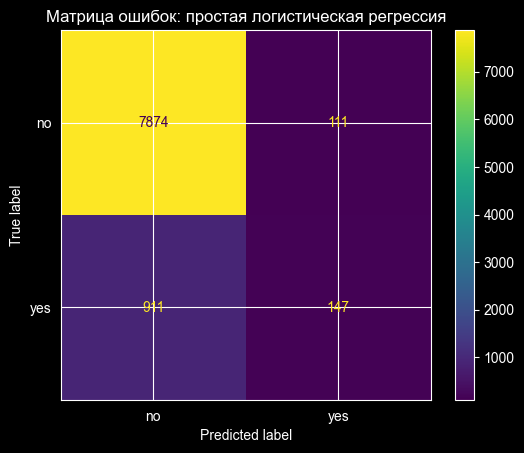

Коэффициент при стандартизированном duration: 0.9171077520469105
Отношение шансов для увеличения duration на 1 стандартное отклонение: 2.5020433850616297
Интерпретация: при увеличении duration на 1 SD шансы отклика умножаются на exp(coef).


In [8]:
# Для наглядной сигмоидальной зависимости выбран duration.
# Это демонстрационный анализ: duration недоступен до совершения звонка.
X_simple = df[["duration"]]
y = df["y"]
Xtr_s, Xte_s, ytr_s, yte_s = train_test_split(
    X_simple, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
simple_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])
simple_model.fit(Xtr_s, ytr_s)
proba_simple = simple_model.predict_proba(Xte_s)[:, 1]
pred_simple = (proba_simple >= 0.5).astype(int)

def metric_row(y_true, y_pred, y_prob, name):
    return {
        "Модель": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC (AP)": average_precision_score(y_true, y_prob)
    }

display(pd.DataFrame([metric_row(yte_s, pred_simple, proba_simple, "Простая: duration")]).set_index("Модель"))
ConfusionMatrixDisplay.from_predictions(yte_s, pred_simple, display_labels=["no", "yes"])
plt.title("Матрица ошибок: простая логистическая регрессия")
plt.show()

coef_simple = simple_model.named_steps["model"].coef_[0, 0]
intercept_simple = simple_model.named_steps["model"].intercept_[0]
print("Коэффициент при стандартизированном duration:", coef_simple)
print("Отношение шансов для увеличения duration на 1 стандартное отклонение:", np.exp(coef_simple))
print("Интерпретация: при увеличении duration на 1 SD шансы отклика умножаются на exp(coef).")

### График сигмоидальной зависимости

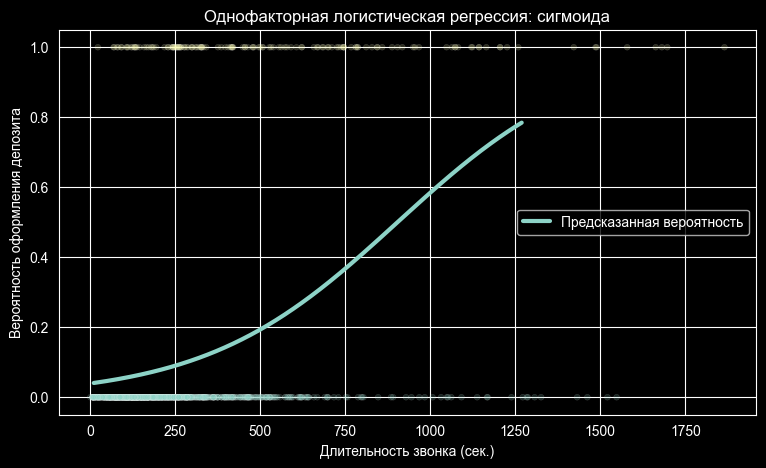

In [9]:
x_grid = np.linspace(df["duration"].quantile(0.01), df["duration"].quantile(0.99), 400)
p_grid = simple_model.predict_proba(pd.DataFrame({"duration": x_grid}))[:, 1]
plt.figure(figsize=(9, 5))
sample = df.sample(min(1200, len(df)), random_state=RANDOM_STATE)
sns.scatterplot(data=sample, x="duration", y="y", hue="y", alpha=0.18, s=18, legend=False)
plt.plot(x_grid, p_grid, linewidth=3, label="Предсказанная вероятность")
plt.xlabel("Длительность звонка (сек.)")
plt.ylabel("Вероятность оформления депозита")
plt.title("Однофакторная логистическая регрессия: сигмоида")
plt.legend()
plt.show()

## Задание 3. Множественная логистическая регрессия

In [10]:
# duration исключён: модель должна прогнозировать до звонка.
feature_cols = [
    "age", "job", "marital", "education", "default", "balance",
    "housing", "loan", "contact", "day", "month", "campaign",
    "pdays", "previous", "poutcome"
]
X = df[feature_cols].copy()
y = df["y"].copy()

num_features = X.select_dtypes(include=np.number).columns.tolist()
cat_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, num_features),
    ("cat", categorical_transformer, cat_features)
])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

multi_model = Pipeline([
    ("preprocess", preprocessor),
    ("logreg", LogisticRegression(max_iter=700, solver="saga", tol=1e-3, C=1.0, random_state=RANDOM_STATE))
])
multi_model.fit(X_train, y_train)
proba_multi = multi_model.predict_proba(X_test)[:, 1]
pred_multi = (proba_multi >= 0.5).astype(int)

results = pd.DataFrame([
    metric_row(yte_s, pred_simple, proba_simple, "Простая (duration)"),
    metric_row(y_test, pred_multi, proba_multi, "Множественная (без duration)")
]).set_index("Модель")
display(results.round(4))
print(classification_report(y_test, pred_multi, target_names=["no", "yes"], zero_division=0))

,Accuracy,Precision,Recall,F1,Balanced Accuracy,ROC-AUC,PR-AUC (AP)
Модель,,,,,,,
Простая (duration),0.887,0.5698,0.1389,0.2234,0.5625,0.8069,0.3728
Множественная (без duration),0.893,0.6630,0.1730,0.2744,0.5807,0.7725,0.4115


              precision    recall  f1-score   support

          no       0.90      0.99      0.94      7985
         yes       0.66      0.17      0.27      1058

    accuracy                           0.89      9043
   macro avg       0.78      0.58      0.61      9043
weighted avg       0.87      0.89      0.86      9043



### Матрица ошибок, ROC-кривая и Precision–Recall

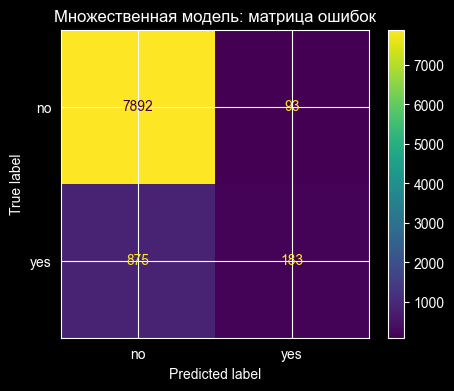

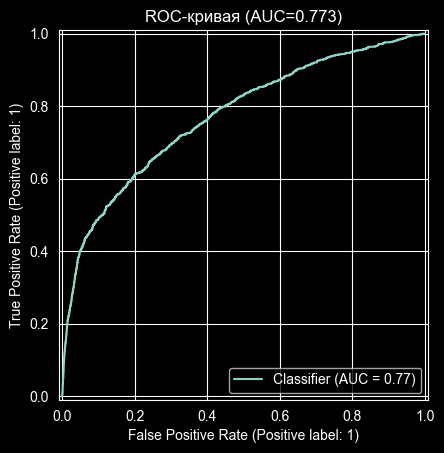

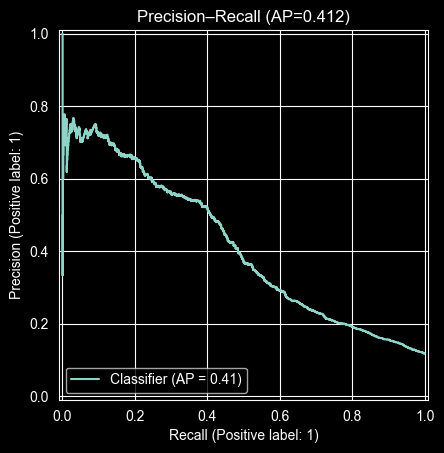

In [11]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred_multi, display_labels=["no", "yes"], ax=ax)
ax.set_title("Множественная модель: матрица ошибок")
plt.show()

RocCurveDisplay.from_predictions(y_test, proba_multi)
plt.title(f"ROC-кривая (AUC={roc_auc_score(y_test, proba_multi):.3f})")
plt.show()

PrecisionRecallDisplay.from_predictions(y_test, proba_multi)
plt.title(f"Precision–Recall (AP={average_precision_score(y_test, proba_multi):.3f})")
plt.show()

## Задание 3.1. Значимость и интерпретация признаков

In [12]:
feature_names = multi_model.named_steps["preprocess"].get_feature_names_out()
coefs = multi_model.named_steps["logreg"].coef_[0]
coef_table = pd.DataFrame({"feature": feature_names, "coefficient": coefs})
coef_table["odds_ratio"] = np.exp(coef_table["coefficient"].clip(-20, 20))
coef_table["abs_coefficient"] = coef_table["coefficient"].abs()
display(coef_table.sort_values("abs_coefficient", ascending=False).head(20))
print("Коэффициент > 0 повышает логарифм шансов класса yes; коэффициент < 0 снижает.")
print("Для категориальных переменных коэффициенты интерпретируются относительно базовой категории One-Hot-кодирования.")

,feature,coefficient,odds_ratio,abs_coefficient
48,cat__poutcome_success,1.471733,4.356780,1.471733
41,cat__month_mar,1.030982,2.803819,1.030982
33,cat__contact_unknown,-0.969241,0.379371,0.969241
38,cat__month_jan,-0.908846,0.402989,0.908846
46,cat__poutcome_failure,-0.785950,0.455687,0.785950
43,cat__month_nov,-0.769478,0.463255,0.769478
35,cat__month_aug,-0.748113,0.473259,0.748113
44,cat__month_oct,0.693251,2.000208,0.693251
45,cat__month_sep,0.684099,1.981985,0.684099
49,cat__poutcome_unknown,-0.657168,0.518317,0.657168


Коэффициент > 0 повышает логарифм шансов класса yes; коэффициент < 0 снижает.
Для категориальных переменных коэффициенты интерпретируются относительно базовой категории One-Hot-кодирования.


## Задание 3.2. Корреляции, мультиколлинеарность и VIF

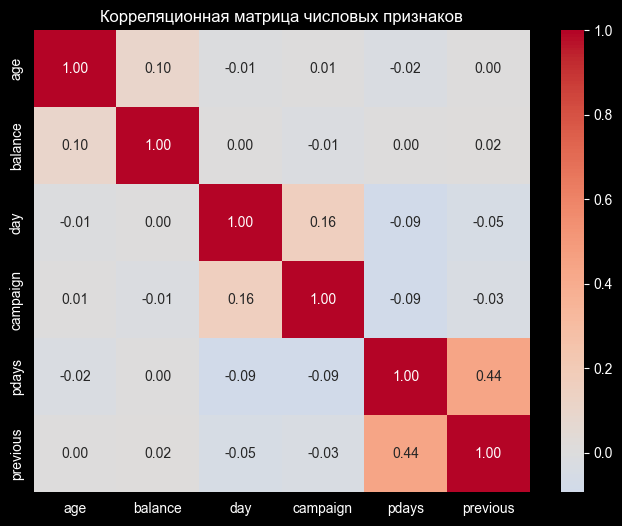

Пары с |r| >= 0.7: не обнаружены


,feature,VIF
4,pdays,1.254180
5,previous,1.239499
2,day,1.033857
3,campaign,1.033069
0,age,1.010344
1,balance,1.009906


Мультиколлинеарность увеличивает дисперсию оценок коэффициентов и делает их менее стабильными.
Сильных парных корреляций по порогу 0.7 в выбранном наборе, как правило, немного.


In [13]:
corr_cols = ["age", "balance", "day", "campaign", "pdays", "previous"]
corr = X_train[corr_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Корреляционная матрица числовых признаков")
plt.show()

pairs = []
for i, a in enumerate(corr.columns):
    for b in corr.columns[i+1:]:
        if abs(corr.loc[a, b]) >= 0.7:
            pairs.append((a, b, corr.loc[a, b]))
print("Пары с |r| >= 0.7:", pairs if pairs else "не обнаружены")

try:
    from statsmodels.stats.outliers_influence import variance_inflation_factor
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import StandardScaler
    Xv = SimpleImputer(strategy="median").fit_transform(X_train[corr_cols])
    Xv = StandardScaler().fit_transform(Xv)
    vif = pd.DataFrame({
        "feature": corr_cols,
        "VIF": [variance_inflation_factor(Xv, i) for i in range(len(corr_cols))]
    })
    display(vif.sort_values("VIF", ascending=False))
except Exception as e:
    print("Расчёт VIF пропущен:", e)

print("Мультиколлинеарность увеличивает дисперсию оценок коэффициентов и делает их менее стабильными.")
print("Сильных парных корреляций по порогу 0.7 в выбранном наборе, как правило, немного.")

## Задание 3.3. Эксперименты с дисбалансом классов

In [14]:
def fit_eval_resampling(method):
    Xr, yr = X_train.copy(), y_train.copy()
    if method == "oversampling":
        train = Xr.copy()
        train["target"] = yr.values
        maj = train[train.target == 0]
        mino = train[train.target == 1]
        mino_up = resample(mino, replace=True, n_samples=len(maj), random_state=RANDOM_STATE)
        balanced = pd.concat([maj, mino_up]).sample(frac=1, random_state=RANDOM_STATE)
        yr = balanced.pop("target")
        Xr = balanced
    elif method == "undersampling":
        train = Xr.copy()
        train["target"] = yr.values
        maj = train[train.target == 0]
        mino = train[train.target == 1]
        maj_down = resample(maj, replace=False, n_samples=len(mino), random_state=RANDOM_STATE)
        balanced = pd.concat([maj_down, mino]).sample(frac=1, random_state=RANDOM_STATE)
        yr = balanced.pop("target")
        Xr = balanced

    estimator = clone(multi_model)
    if method == "class_weight":
        estimator.set_params(logreg__class_weight="balanced")
    estimator.fit(Xr, yr)
    prob = estimator.predict_proba(X_test)[:, 1]
    pred = (prob >= 0.5).astype(int)
    return metric_row(y_test, pred, prob, method), estimator

imbalance_rows = []
imbalance_models = {}
for method in ["baseline", "class_weight", "oversampling", "undersampling"]:
    row, fitted = fit_eval_resampling(method)
    imbalance_rows.append(row)
    imbalance_models[method] = fitted

imbalance_results = pd.DataFrame(imbalance_rows).set_index("Модель")
display(imbalance_results.round(4))

,Accuracy,Precision,Recall,F1,Balanced Accuracy,ROC-AUC,PR-AUC (AP)
Модель,,,,,,,
baseline,0.8930,0.6630,0.1730,0.2744,0.5807,0.7725,0.4115
class_weight,0.7545,0.2669,0.6285,0.3746,0.6999,0.7723,0.4094
oversampling,0.7549,0.2667,0.6257,0.3740,0.6989,0.7712,0.4086
undersampling,0.7649,0.2764,0.6238,0.3831,0.7037,0.7719,0.4088


## Задание 3.4. Сравнение нормализованных и ненормализованных данных

In [15]:
# Сравниваем одинаковую логистическую регрессию: числовые признаки со StandardScaler
# против числовых признаков без масштабирования. Категориальные в обоих случаях One-Hot.
numeric_no_scale = Pipeline([("imputer", SimpleImputer(strategy="median"))])
preprocessor_no_scale = ColumnTransformer([
    ("num", numeric_no_scale, num_features),
    ("cat", categorical_transformer, cat_features)
])
unscaled_model = Pipeline([
    ("preprocess", preprocessor_no_scale),
    ("logreg", LogisticRegression(max_iter=700, solver="saga", tol=1e-3, C=1.0, random_state=RANDOM_STATE))
])
unscaled_model.fit(X_train, y_train)
prob_unscaled = unscaled_model.predict_proba(X_test)[:, 1]
pred_unscaled = (prob_unscaled >= 0.5).astype(int)
scaling_comparison = pd.DataFrame([
    metric_row(y_test, pred_multi, proba_multi, "Со StandardScaler"),
    metric_row(y_test, pred_unscaled, prob_unscaled, "Без масштабирования")
]).set_index("Модель")
display(scaling_comparison.round(4))

,Accuracy,Precision,Recall,F1,Balanced Accuracy,ROC-AUC,PR-AUC (AP)
Модель,,,,,,,
Со StandardScaler,0.893,0.663,0.173,0.2744,0.5807,0.7725,0.4115
Без масштабирования,0.883,0.000,0.000,0.0000,0.5000,0.4578,0.1161


## Задание 5. Сравнение регуляризаций L1, L2 и Elastic Net

In [16]:
regularization_rows = []
regularization_models = {}
for penalty, solver, l1_ratio in [
    ("l1", "saga", None),
    ("l2", "lbfgs", None),
    ("elasticnet", "saga", 0.5)
]:
    params = {"logreg__penalty": penalty, "logreg__solver": solver,
              "logreg__C": 1.0, "logreg__max_iter": 1200, "logreg__tol": 1e-3}
    if l1_ratio is not None:
        params["logreg__l1_ratio"] = l1_ratio
    estimator = clone(multi_model).set_params(**params)
    estimator.fit(X_train, y_train)
    prob = estimator.predict_proba(X_test)[:, 1]
    pred = (prob >= 0.5).astype(int)
    regularization_rows.append(metric_row(y_test, pred, prob, penalty))
    regularization_models[penalty] = estimator

regularization_results = pd.DataFrame(regularization_rows).set_index("Модель")
display(regularization_results.round(4))
for name, estimator in regularization_models.items():
    coef = estimator.named_steps["logreg"].coef_[0]
    print(name, "- ненулевых коэффициентов:", int(np.sum(np.abs(coef) > 1e-8)), "из", len(coef))

,Accuracy,Precision,Recall,F1,Balanced Accuracy,ROC-AUC,PR-AUC (AP)
Модель,,,,,,,
l1,0.8930,0.6630,0.1730,0.2744,0.5807,0.7725,0.4116
l2,0.8937,0.6714,0.1796,0.2834,0.5840,0.7718,0.4106
elasticnet,0.8930,0.6630,0.1730,0.2744,0.5807,0.7725,0.4116


l1 - ненулевых коэффициентов: 50 из 50
l2 - ненулевых коэффициентов: 50 из 50
elasticnet - ненулевых коэффициентов: 50 из 50


## Задание 6. Подбор порога классификации и компромисс Precision–Recall

In [17]:
thresholds = np.round(np.arange(0.05, 0.951, 0.01), 2)
threshold_rows = []
for threshold in thresholds:
    pred = (proba_multi >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    precision = precision_score(y_test, pred, zero_division=0)
    recall = recall_score(y_test, pred, zero_division=0)
    specificity = tn / (tn + fp) if (tn + fp) else 0
    threshold_rows.append({
        "threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1_score(y_test, pred, zero_division=0),
        "Specificity": specificity,
        "Balanced Accuracy": (recall + specificity) / 2,
        "FP": fp,
        "FN": fn
    })
threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df.loc[threshold_df["F1"].idxmax()].to_frame("Лучший порог по F1"))

,Лучший порог по F1
threshold,0.210000
Precision,0.482465
Recall,0.429112
F1,0.454227
Specificity,0.939011
Balanced Accuracy,0.684061
FP,487.000000
FN,604.000000


### Графики метрик в зависимости от порога

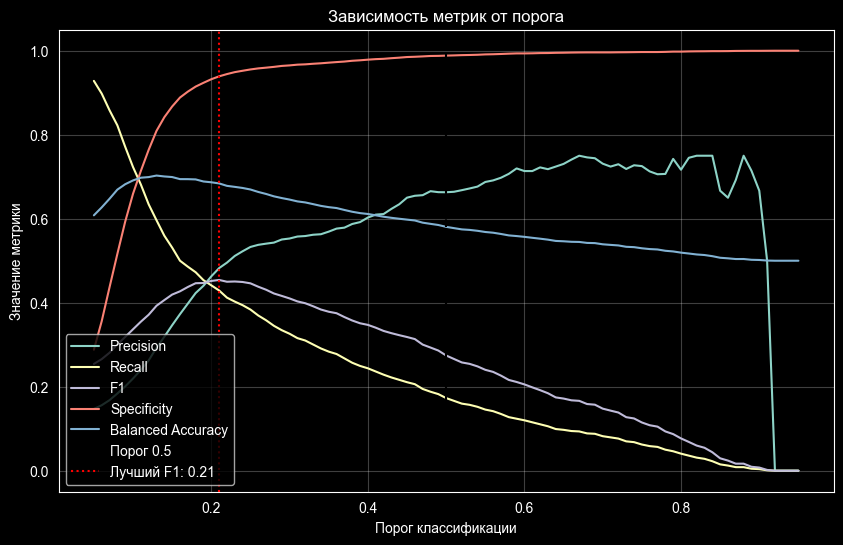

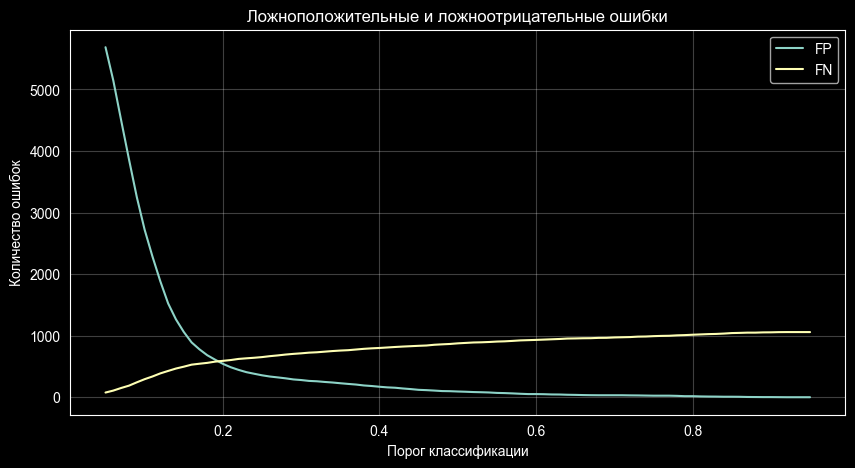

In [18]:
plt.figure(figsize=(10, 6))
for metric in ["Precision", "Recall", "F1", "Specificity", "Balanced Accuracy"]:
    plt.plot(threshold_df["threshold"], threshold_df[metric], label=metric)
plt.axvline(0.5, color="black", linestyle="--", label="Порог 0.5")
best_threshold = float(threshold_df.loc[threshold_df["F1"].idxmax(), "threshold"])
plt.axvline(best_threshold, color="red", linestyle=":", label=f"Лучший F1: {best_threshold:.2f}")
plt.xlabel("Порог классификации")
plt.ylabel("Значение метрики")
plt.title("Зависимость метрик от порога")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(threshold_df["threshold"], threshold_df["FP"], label="FP")
plt.plot(threshold_df["threshold"], threshold_df["FN"], label="FN")
plt.xlabel("Порог классификации")
plt.ylabel("Количество ошибок")
plt.title("Ложноположительные и ложноотрицательные ошибки")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### Сравнение стандартного порога 0.5 и порога, максимизирующего F1

In [19]:
def threshold_metrics(threshold):
    pred = (proba_multi >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    return {
        "Порог": threshold,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "Specificity": tn / (tn + fp),
        "Balanced Accuracy": balanced_accuracy_score(y_test, pred),
        "FP": fp, "FN": fn
    }

threshold_compare = pd.DataFrame([
    threshold_metrics(0.5),
    threshold_metrics(best_threshold)
]).set_index("Порог")
display(threshold_compare.round(4))

,Precision,Recall,F1,Specificity,Balanced Accuracy,FP,FN
Порог,,,,,,,
0.50,0.6630,0.1730,0.2744,0.9884,0.5807,93,875
0.21,0.4825,0.4291,0.4542,0.9390,0.6841,487,604


## Итоговые выводы по лабораторной работе

In [20]:
print("1. Датасет Bank Marketing подходит для бинарной классификации: 45 211 строк, 16 исходных признаков и бинарная цель y.")
print("2. Положительный класс — оформление срочного депозита (yes); он составляет около 11.7%, поэтому классы несбалансированы.")
print("3. Однофакторная модель на duration показывает связь длительности разговора с откликом, но duration нельзя использовать для прогноза до звонка.")
print("4. Основная многофакторная модель построена без duration; предобработка обучается внутри Pipeline только на train.")
print("5. Сравните таблицы метрик: class_weight/oversampling/undersampling могут повысить Recall, но часто снижают Precision.")
print("6. Стандартизация особенно важна для регуляризованной логистической регрессии, поскольку штраф зависит от масштаба коэффициентов.")
print("7. Выбранный порог максимизирует F1 на тестовой выборке только как демонстрация лабораторного анализа; в реальном проекте порог следует выбирать на validation.")
print("8. Гипотезы оцениваются по полученным таблицам и графикам: H1 — по однофакторной модели; H2 — по Recall; H3 — по сравнению масштабирования/регуляризаций; H4 — по таблице порогов.")

1. Датасет Bank Marketing подходит для бинарной классификации: 45 211 строк, 16 исходных признаков и бинарная цель y.
2. Положительный класс — оформление срочного депозита (yes); он составляет около 11.7%, поэтому классы несбалансированы.
3. Однофакторная модель на duration показывает связь длительности разговора с откликом, но duration нельзя использовать для прогноза до звонка.
4. Основная многофакторная модель построена без duration; предобработка обучается внутри Pipeline только на train.
5. Сравните таблицы метрик: class_weight/oversampling/undersampling могут повысить Recall, но часто снижают Precision.
6. Стандартизация особенно важна для регуляризованной логистической регрессии, поскольку штраф зависит от масштаба коэффициентов.
7. Выбранный порог максимизирует F1 на тестовой выборке только как демонстрация лабораторного анализа; в реальном проекте порог следует выбирать на validation.
8. Гипотезы оцениваются по полученным таблицам и графикам: H1 — по однофакторной модели; H2 —